# Customer Sales & Behaviour Analysis

### End-to-End Python Data Analytics Project

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab

**Dataset:** Dunnhumby — The Complete Journey

## Project Overview

This project analyses retail transaction data to understand customer purchasing behaviour, revenue trends, shopping basket patterns, and product performance.

The analysis uses approximately 2.6 million transaction records covering 2,500 households over 102 weeks.

The project follows a complete data analytics workflow, from data understanding and cleaning to exploratory analysis, customer segmentation, visualization, and business recommendations.

## Project Objectives

- Analyse overall sales performance and weekly revenue trends.
- Examine shopping basket values and customer purchase frequency.
- Identify high-revenue departments and product categories.
- Measure customer revenue concentration.
- Segment households using Recency, Frequency, and Monetary (RFM) analysis.
- Develop evidence-based business insights and recommendations.

## Dataset & Methodology

The project uses transaction, product, and household demographic data from the Dunnhumby Complete Journey dataset.

Data preparation includes validating unique identifiers, investigating missing values and unusual transactions, filtering zero-sales records for revenue analysis, and merging transactions with product information.

Customer segmentation uses quintile-based RFM scoring and project-defined behavioural categories.

## Analysis Workflow

1. Data Loading & Understanding
2. Data Cleaning & Preparation
3. Exploratory Data Analysis
4. RFM Customer Segmentation
5. Business Insights & Recommendations

## Important Notes

- Sales value represents recorded retailer revenue rather than necessarily the customer's out-of-pocket spending.
- Time is measured using relative day and week numbers.
- Demographic information is available for only a subset of households.
- RFM segments describe historical purchasing behaviour and do not establish actual churn or future outcomes.

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Project environment ready!")

Project environment ready!


In [56]:
# Mount Google Drive only if the dataset
# is not already available locally.

import os

if not os.path.isdir("/content/data"):
    from google.colab import drive
    drive.mount("/content/drive")
else:
    print("Using locally uploaded dataset.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
import os

# Use Google Drive if the data folder exists there.
# Otherwise, use a local Colab data folder.

drive_path = "/content/drive/MyDrive/data"
local_path = "/content/data"

if os.path.isdir(drive_path):
    DATA_PATH = drive_path
else:
    DATA_PATH = local_path

if not os.path.isdir(DATA_PATH):
    raise FileNotFoundError(
        "Dataset folder not found. Download the Dunnhumby "
        "Complete Journey dataset and place the CSV files "
        "inside a folder named 'data'."
    )

print("Dataset location:", DATA_PATH)

Dataset location: /content/drive/MyDrive/data


In [58]:
import pandas as pd
import os


for file in os.listdir(DATA_PATH):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(DATA_PATH, file), nrows=5)

        print("\n" + "=" * 65)
        print(f"FILE: {file}")
        print("=" * 65)

        print("Columns:", df.columns.tolist())
        print("\nData Types:")
        print(df.dtypes)
        print("\nSample Records:")
        display(df.head(3))


FILE: campaign_desc.csv
Columns: ['DESCRIPTION', 'CAMPAIGN', 'START_DAY', 'END_DAY']

Data Types:
DESCRIPTION    object
CAMPAIGN        int64
START_DAY       int64
END_DAY         int64
dtype: object

Sample Records:


,DESCRIPTION,CAMPAIGN,START_DAY,END_DAY
0,TypeB,24,659,719
1,TypeC,15,547,708
2,TypeB,25,659,691



FILE: campaign_table.csv
Columns: ['DESCRIPTION', 'household_key', 'CAMPAIGN']

Data Types:
DESCRIPTION      object
household_key     int64
CAMPAIGN          int64
dtype: object

Sample Records:


,DESCRIPTION,household_key,CAMPAIGN
0,TypeA,17,26
1,TypeA,27,26
2,TypeA,212,26



FILE: causal_data.csv
Columns: ['PRODUCT_ID', 'STORE_ID', 'WEEK_NO', 'display', 'mailer']

Data Types:
PRODUCT_ID     int64
STORE_ID       int64
WEEK_NO        int64
display        int64
mailer        object
dtype: object

Sample Records:


,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
0,26190,286,70,0,A
1,26190,288,70,0,A
2,26190,289,70,0,A


... (6 outputs left out)


FILE: product.csv
Columns: ['PRODUCT_ID', 'MANUFACTURER', 'DEPARTMENT', 'BRAND', 'COMMODITY_DESC', 'SUB_COMMODITY_DESC', 'CURR_SIZE_OF_PRODUCT']

Data Types:
PRODUCT_ID               int64
MANUFACTURER             int64
DEPARTMENT              object
BRAND                   object
COMMODITY_DESC          object
SUB_COMMODITY_DESC      object
CURR_SIZE_OF_PRODUCT    object
dtype: object

Sample Records:


,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,



FILE: transaction_data.csv
Columns: ['household_key', 'BASKET_ID', 'DAY', 'PRODUCT_ID', 'QUANTITY', 'SALES_VALUE', 'STORE_ID', 'RETAIL_DISC', 'TRANS_TIME', 'WEEK_NO', 'COUPON_DISC', 'COUPON_MATCH_DISC']

Data Types:
household_key          int64
BASKET_ID              int64
DAY                    int64
PRODUCT_ID             int64
QUANTITY               int64
SALES_VALUE          float64
STORE_ID               int64
RETAIL_DISC          float64
TRANS_TIME             int64
WEEK_NO                int64
COUPON_DISC            int64
COUPON_MATCH_DISC      int64
dtype: object

Sample Records:


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.6,1631,1,0,0
1,2375,26984851472,1,1033142,1,0.82,364,0.0,1631,1,0,0
2,2375,26984851472,1,1036325,1,0.99,364,-0.3,1631,1,0,0


In [59]:
import os
import pandas as pd

for file in sorted(os.listdir(DATA_PATH)):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(DATA_PATH, file), nrows=5)

        print(f"\n{'='*50}")
        print("FILE:", file)
        print("COLUMNS:", df.columns.tolist())
        print("SAMPLE DATA:")
        print(df.head(2).to_string(index=False))


FILE: campaign_desc.csv
COLUMNS: ['DESCRIPTION', 'CAMPAIGN', 'START_DAY', 'END_DAY']
SAMPLE DATA:
DESCRIPTION  CAMPAIGN  START_DAY  END_DAY
      TypeB        24        659      719
      TypeC        15        547      708

FILE: campaign_table.csv
COLUMNS: ['DESCRIPTION', 'household_key', 'CAMPAIGN']
SAMPLE DATA:
DESCRIPTION  household_key  CAMPAIGN
      TypeA             17        26
      TypeA             27        26

FILE: causal_data.csv
COLUMNS: ['PRODUCT_ID', 'STORE_ID', 'WEEK_NO', 'display', 'mailer']
SAMPLE DATA:
 PRODUCT_ID  STORE_ID  WEEK_NO  display mailer
      26190       286       70        0      A
      26190       288       70        0      A

FILE: coupon.csv
COLUMNS: ['COUPON_UPC', 'PRODUCT_ID', 'CAMPAIGN']
SAMPLE DATA:
 COUPON_UPC  PRODUCT_ID  CAMPAIGN
10000089061       27160         4
10000089064       27754         9

FILE: coupon_redempt.csv
COLUMNS: ['household_key', 'DAY', 'COUPON_UPC', 'CAMPAIGN']
SAMPLE DATA:
 household_key  DAY  COUPON_UPC  CAMPAIGN
  

In [60]:
files = [
    "campaign_desc",
    "campaign_table",
    "coupon",
    "coupon_redempt",
    "hh_demographic",
    "product",
    "transaction_data"
]

data = {}

for file in files:
    df = pd.read_csv(os.path.join(DATA_PATH, file + ".csv"))

    # Standardize column names
    df.columns = df.columns.str.lower()

    data[file] = df

    print(f"\n{'='*45}")
    print(f"Dataset: {file}")
    print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
    print(f"Duplicate rows: {df.duplicated().sum():,}")
    print(f"Missing values: {df.isnull().sum().sum():,}")


Dataset: campaign_desc
Rows: 30 | Columns: 4
Duplicate rows: 0
Missing values: 0

Dataset: campaign_table
Rows: 7,208 | Columns: 3
Duplicate rows: 0
Missing values: 0

Dataset: coupon
Rows: 124,548 | Columns: 3
Duplicate rows: 5,164
Missing values: 0

Dataset: coupon_redempt
Rows: 2,318 | Columns: 4
Duplicate rows: 0
Missing values: 0

Dataset: hh_demographic
Rows: 801 | Columns: 8
Duplicate rows: 0
Missing values: 0

Dataset: product
Rows: 92,353 | Columns: 7
Duplicate rows: 0
Missing values: 0

Dataset: transaction_data
Rows: 2,595,732 | Columns: 12
Duplicate rows: 0
Missing values: 0


In [61]:
transactions = data["transaction_data"]

print("Dataset Shape:", transactions.shape)

print("\nColumn Information:")
transactions.info()

print("\nStatistical Summary:")
display(transactions.describe().round(2))

print("\nFirst 5 Records:")
display(transactions.head())

Dataset Shape: (2595732, 12)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   basket_id          int64  
 2   day                int64  
 3   product_id         int64  
 4   quantity           int64  
 5   sales_value        float64
 6   store_id           int64  
 7   retail_disc        float64
 8   trans_time         int64  
 9   week_no            int64  
 10  coupon_disc        float64
 11  coupon_match_disc  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB

Statistical Summary:


,household_key,basket_id,day,product_id,quantity,sales_value,store_id,retail_disc,trans_time,week_no,coupon_disc,coupon_match_disc
count,2595732.00,2.595732e+06,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00,2595732.00
mean,1271.95,3.402620e+10,388.76,2891435.16,100.43,3.10,3142.67,-0.54,1561.59,56.22,-0.02,-0.00
std,726.07,4.711649e+09,189.72,3837403.69,1153.44,4.18,8937.11,1.25,399.84,27.10,0.22,0.04
min,1.00,2.698485e+10,1.00,25671.00,0.00,0.00,1.00,-180.00,0.00,1.00,-55.93,-7.70
25%,656.00,3.040805e+10,229.00,917459.00,1.00,1.29,330.00,-0.69,1308.00,33.00,0.00,0.00
50%,1272.00,3.276081e+10,390.00,1028816.00,1.00,2.00,372.00,-0.01,1613.00,56.00,0.00,0.00
75%,1913.00,4.012685e+10,553.00,1133018.00,1.00,3.49,422.00,0.00,1843.00,80.00,0.00,0.00
max,2500.00,4.230536e+10,711.00,18316298.00,89638.00,840.00,34280.00,3.99,2359.00,102.00,0.00,0.00



First 5 Records:


,household_key,basket_id,day,product_id,quantity,sales_value,store_id,retail_disc,trans_time,week_no,coupon_disc,coupon_match_disc
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


In [62]:
print("1. Quantity distribution:")
display(transactions["quantity"].describe(
    percentiles=[.50, .75, .90, .95, .99, .999]
).to_frame())

print("\n2. Unusual value counts:")
print("Zero quantity:", (transactions["quantity"] == 0).sum())
print("Negative quantity:", (transactions["quantity"] < 0).sum())
print("Quantity above 100:", (transactions["quantity"] > 100).sum())
print("Zero sales value:", (transactions["sales_value"] == 0).sum())
print("Negative sales value:", (transactions["sales_value"] < 0).sum())
print("Positive retail discounts:", (transactions["retail_disc"] > 0).sum())

print("\n3. Ten records with the highest quantities:")
display(
    transactions.nlargest(10, "quantity")[
        ["household_key", "basket_id", "product_id",
         "quantity", "sales_value", "retail_disc"]
    ]
)

print("\n4. Most common quantity values:")
display(transactions["quantity"].value_counts().head(15).to_frame("Frequency"))

1. Quantity distribution:


,quantity
count,2.595732e+06
mean,1.004286e+02
std,1.153436e+03
min,0.000000e+00
50%,1.000000e+00
75%,1.000000e+00
90%,2.000000e+00
95%,3.000000e+00
99%,1.000000e+01
99.9%,1.694354e+04



2. Unusual value counts:
Zero quantity: 14466
Negative quantity: 0
Quantity above 100: 23136
Zero sales value: 18850
Negative sales value: 0
Positive retail discounts: 36

3. Ten records with the highest quantities:


,household_key,basket_id,product_id,quantity,sales_value,retail_disc
1750942,630,34749153595,6534178,89638,250.00,-13.45
468356,2407,29392047893,6544236,85055,210.00,-8.51
481876,630,29484790880,6534178,61335,150.21,-6.13
166536,149,28210551971,6534178,51912,110.00,-5.19
1340882,193,32956767959,6534178,48073,121.10,-7.21
2472791,2133,41904760458,6534178,45475,100.00,-4.55
1560340,149,33768630428,6534178,41833,115.00,-4.18
376686,149,29035716247,6534178,41686,100.00,-4.17
156049,1406,28167562655,6544236,41485,85.00,-4.15
87625,107,27865225627,6534178,39365,72.00,-3.94



4. Most common quantity values:


,Frequency
quantity,
1,2050967
2,372373
3,66962
4,38667
0,14466
5,10918
6,8981
8,2531
10,2219


In [63]:
unusual_products = [6534178, 6544236]

display(
    data["product"][
        data["product"]["product_id"].isin(unusual_products)
    ]
)

,product_id,manufacturer,department,brand,commodity_desc,sub_commodity_desc,curr_size_of_product
57221,6534178,69,KIOSK-GAS,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,
57335,6544236,69,MISC SALES TRAN,Private,COUPON/MISC ITEMS,GASOLINE-REG UNLEADED,


In [64]:
zero_sales = transactions[transactions["sales_value"] == 0]

print("Zero-sales records:", len(zero_sales))

display(
    zero_sales[
        ["household_key", "basket_id", "product_id",
         "quantity", "sales_value", "retail_disc",
         "coupon_disc", "coupon_match_disc"]
    ].head(10)
)

Zero-sales records: 18850


,household_key,basket_id,product_id,quantity,sales_value,retail_disc,coupon_disc,coupon_match_disc
97,744,26985165432,5978648,0,0.0,0.00,0.0,0.0
128,1287,26985336468,5978648,0,0.0,0.00,0.0,0.0
249,2305,26996870743,5978656,0,0.0,0.00,-1.0,0.0
293,271,26997082949,5978656,0,0.0,0.00,-2.0,0.0
694,315,27008952267,957951,0,0.0,0.00,0.0,0.0
766,2110,27009082349,837963,1,0.0,0.00,0.0,0.0
996,568,27021090189,951412,1,0.0,-1.48,0.0,0.0
1089,14,27021203242,6463658,0,0.0,0.00,0.0,0.0
1095,2110,27021248054,850115,1,0.0,-3.29,0.0,0.0
1113,2110,27021248054,976872,1,0.0,-2.49,0.0,0.0


In [65]:
zero_sales = transactions[transactions["sales_value"] == 0]

print("Quantity breakdown:")
display(zero_sales["quantity"].value_counts().to_frame("Records"))

print("\nDiscount summary:")
display(
    zero_sales[
        ["retail_disc", "coupon_disc", "coupon_match_disc"]
    ].describe().round(2)
)

print("\nRecords with zero quantity:")
print((zero_sales["quantity"] == 0).sum())

print("\nRecords with positive quantity:")
print((zero_sales["quantity"] > 0).sum())

print("\nProducts most frequently appearing in zero-sales records:")
display(
    zero_sales["product_id"]
    .value_counts()
    .head(10)
    .to_frame("Zero-sales records")
)

Quantity breakdown:


,Records
quantity,
0,14399
1,4370
2,75
3,5
9,1



Discount summary:


,retail_disc,coupon_disc,coupon_match_disc
count,18850.00,18850.00,18850.00
mean,-0.78,-0.55,-0.00
std,1.82,1.51,0.01
min,-39.95,-37.93,-0.50
25%,0.00,-0.50,0.00
50%,0.00,0.00,0.00
75%,0.00,0.00,0.00
max,0.01,0.00,0.00



Records with zero quantity:
14399

Records with positive quantity:
4451

Products most frequently appearing in zero-sales records:


,Zero-sales records
product_id,
5978656,4887
5978648,2867
1053460,323
1014948,111
897752,93
1079228,93
1132911,75
910032,71
1102959,68


In [66]:
product_ids = [5978656, 5978648]

display(
    data["product"][
        data["product"]["product_id"].isin(product_ids)
    ]
)


,product_id,manufacturer,department,brand,commodity_desc,sub_commodity_desc,curr_size_of_product
55054,5978648,1,,National,,,
55057,5978656,1,,National,,,


In [67]:
print("Total transaction rows:", len(transactions))

print("Unique baskets:", transactions["basket_id"].nunique())

print("Unique households:", transactions["household_key"].nunique())

print("\nBasket IDs linked to multiple households:")
basket_households = transactions.groupby("basket_id")["household_key"].nunique()
print((basket_households > 1).sum())

print("\nAverage product lines per basket:")
print(round(len(transactions) / transactions["basket_id"].nunique(), 2))

print("\nHouseholds with the most transaction records:")
display(
    transactions["household_key"]
    .value_counts()
    .head(10)
    .to_frame("Transaction records")
)

Total transaction rows: 2595732
Unique baskets: 276484
Unique households: 2500

Basket IDs linked to multiple households:
0

Average product lines per basket:
9.39

Households with the most transaction records:


,Transaction records
household_key,
718,6851
2459,6646
1609,6625
1111,6576
1453,6561
982,5806
2322,5692
371,5669
1489,5586


In [68]:
import gc

# Remove the large optional dataset from memory
data.pop("causal_data", None)
gc.collect()

# Create working copies of our main datasets
clean_data = {
    "transaction_data": data["transaction_data"].copy(),
    "product": data["product"].copy(),
    "hh_demographic": data["hh_demographic"].copy()
}

# Update our main transaction reference
transactions = clean_data["transaction_data"]

print("Working datasets created successfully!")

for name, df in clean_data.items():
    print(f"{name}: {df.shape}")

Working datasets created successfully!
transaction_data: (2595732, 12)
product: (92353, 7)
hh_demographic: (801, 8)


In [69]:
# Check exact duplicate rows in each working dataset

for name, df in clean_data.items():
    duplicates = df.duplicated().sum()

    print(f"{name}")
    print(f"Total duplicate rows: {duplicates}")
    print("-" * 35)

transaction_data
Total duplicate rows: 0
-----------------------------------
product
Total duplicate rows: 0
-----------------------------------
hh_demographic
Total duplicate rows: 0
-----------------------------------


In [70]:
# Convert empty strings and whitespace-only values into NaN

for name, df in clean_data.items():
    df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# Check missing values
for name, df in clean_data.items():
    print(f"\n{name}")
    print(df.isnull().sum())


transaction_data
household_key        0
basket_id            0
day                  0
product_id           0
quantity             0
sales_value          0
store_id             0
retail_disc          0
trans_time           0
week_no              0
coupon_disc          0
coupon_match_disc    0
dtype: int64

product
product_id                  0
manufacturer                0
department                 15
brand                       0
commodity_desc             15
sub_commodity_desc         15
curr_size_of_product    30607
dtype: int64

hh_demographic
classification_1     0
classification_2     0
classification_3     0
homeowner_desc       0
classification_5     0
classification_4     0
kid_category_desc    0
household_key        0
dtype: int64


In [71]:
# Find products with missing category information

missing_products = clean_data["product"][
    clean_data["product"]["department"].isna()
]

print("Products with missing department information:")
display(missing_products)

Products with missing department information:


,product_id,manufacturer,department,brand,commodity_desc,sub_commodity_desc,curr_size_of_product
52189,5126087,1,NaN,National,NaN,NaN,NaN
52190,5126088,1,NaN,National,NaN,NaN,NaN
52191,5126106,1,NaN,National,NaN,NaN,NaN
52192,5126107,1,NaN,National,NaN,NaN,NaN
55048,5977100,1,NaN,National,NaN,NaN,NaN
55054,5978648,1,NaN,National,NaN,NaN,NaN
55055,5978649,1,NaN,National,NaN,NaN,NaN
55056,5978650,1,NaN,National,NaN,NaN,NaN
55057,5978656,1,NaN,National,NaN,NaN,NaN
55058,5978657,1,NaN,National,NaN,NaN,NaN


In [72]:
products = clean_data["product"]

print("Total products:", len(products))
print("Products with missing size:", products["curr_size_of_product"].isna().sum())
print("Products with available size:", products["curr_size_of_product"].notna().sum())

print("\nPercentage of missing sizes:")
print(round(products["curr_size_of_product"].isna().mean() * 100, 2), "%")

Total products: 92353
Products with missing size: 30607
Products with available size: 61746

Percentage of missing sizes:
33.14 %


In [73]:
# Check uniqueness of important IDs

print("Unique product IDs:", products["product_id"].nunique())
print("Total product records:", len(products))

print("\nUnique demographic household IDs:",
      clean_data["hh_demographic"]["household_key"].nunique())

print("Total demographic records:",
      len(clean_data["hh_demographic"]))

Unique product IDs: 92353
Total product records: 92353

Unique demographic household IDs: 801
Total demographic records: 801


In [74]:
# Find product IDs in transactions that don't exist in the product table

transaction_product_ids = set(transactions["product_id"].unique())
available_product_ids = set(products["product_id"].unique())

unmatched_products = transaction_product_ids - available_product_ids

print("Unique products in transactions:", len(transaction_product_ids))
print("Products available in product dataset:", len(available_product_ids))
print("Unmatched product IDs:", len(unmatched_products))

Unique products in transactions: 92339
Products available in product dataset: 92353
Unmatched product IDs: 0


In [75]:
# Check household matching

transaction_households = set(transactions["household_key"].unique())

demographic_households = set(
    clean_data["hh_demographic"]["household_key"].unique()
)

matched_households = transaction_households & demographic_households

print("Households in transactions:", len(transaction_households))
print("Households in demographics:", len(demographic_households))
print("Households with demographic information:", len(matched_households))
print("Households without demographic information:",
      len(transaction_households - demographic_households))

Households in transactions: 2500
Households in demographics: 801
Households with demographic information: 801
Households without demographic information: 1699


In [76]:
# Check unusual transaction values

print("Zero quantity:", (transactions["quantity"] == 0).sum())
print("Negative quantity:", (transactions["quantity"] < 0).sum())
print("Quantity above 100:", (transactions["quantity"] > 100).sum())

print("\nZero sales value:", (transactions["sales_value"] == 0).sum())
print("Negative sales value:", (transactions["sales_value"] < 0).sum())

print("\nZero retail discount:", (transactions["retail_disc"] == 0).sum())
print("Positive retail discount:", (transactions["retail_disc"] > 0).sum())

Zero quantity: 14466
Negative quantity: 0
Quantity above 100: 23136

Zero sales value: 18850
Negative sales value: 0

Zero retail discount: 1292670
Positive retail discount: 36


In [77]:
# Investigate transactions with zero quantity

zero_qty = transactions[transactions["quantity"] == 0]

print("Total zero-quantity records:", len(zero_qty))

print("Zero quantity with zero sales:",
      (zero_qty["sales_value"] == 0).sum())

print("Zero quantity with positive sales:",
      (zero_qty["sales_value"] > 0).sum())

print("\nTotal sales value of zero-quantity records:")
print(round(zero_qty["sales_value"].sum(), 2))

Total zero-quantity records: 14466
Zero quantity with zero sales: 14399
Zero quantity with positive sales: 67

Total sales value of zero-quantity records:
19.28


In [78]:
# Create a dataset for sales analysis
sales_data = transactions[
    transactions["sales_value"] > 0
].copy()

print("Original transaction rows:", len(transactions))
print("Sales analysis rows:", len(sales_data))
print("Excluded zero-sales rows:", len(transactions) - len(sales_data))

print("\nTotal recorded sales value:")
print(round(transactions["sales_value"].sum(), 2))

print("\nSales value in analysis dataset:")
print(round(sales_data["sales_value"].sum(), 2))

Original transaction rows: 2595732
Sales analysis rows: 2576882
Excluded zero-sales rows: 18850

Total recorded sales value:
8057463.08

Sales value in analysis dataset:
8057463.08


In [79]:
# Merge sales transactions with product information

analysis_data = sales_data.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Sales rows before merge:", len(sales_data))
print("Rows after merge:", len(analysis_data))

print("\nSample of merged dataset:")
display(analysis_data.head())

Sales rows before merge: 2576882
Rows after merge: 2576882

Sample of merged dataset:


,household_key,basket_id,day,product_id,quantity,sales_value,store_id,retail_disc,trans_time,week_no,coupon_disc,coupon_match_disc,manufacturer,department,brand,commodity_desc,sub_commodity_desc,curr_size_of_product
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0,69,PRODUCE,Private,POTATOES,POTATOES RUSSET (BULK&BAG),5 LB
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0,2,PRODUCE,National,ONIONS,ONIONS SWEET (BULK&BAG),40 LB
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0,69,PRODUCE,Private,VEGETABLES - ALL OTHERS,CELERY,NaN
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0,2,PRODUCE,National,TROPICAL FRUIT,BANANAS,40 LB
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0,69,PRODUCE,Private,ORGANICS FRUIT & VEGETABLES,ORGANIC CARROTS,1 LB


In [80]:
# Step 2.2A - Inspect department-level revenue

department_summary = (
    analysis_data.groupby("department", dropna=False)
    .agg(
        transaction_rows=("sales_value", "size"),
        revenue=("sales_value", "sum")
    )
    .sort_values("revenue", ascending=False)
)

department_summary["revenue_share_pct"] = (
    department_summary["revenue"]
    / analysis_data["sales_value"].sum() * 100
)

display(department_summary.round(2))

,transaction_rows,revenue,revenue_share_pct
department,,,
GROCERY,1642330,4093814.14,50.81
DRUG GM,275245,1055358.03,13.10
PRODUCE,255623,557452.11,6.92
MEAT,88083,548786.81,6.81
KIOSK-GAS,22059,544222.28,6.75
MEAT-PCKGD,110796,412436.77,5.12
DELI,62556,260866.51,3.24
PASTRY,37470,121739.86,1.51
MISC SALES TRAN,5986,119960.04,1.49


In [81]:

# Step 2.2B - Create retail-focused comparison dataset

excluded_departments = [
    "KIOSK-GAS",
    "MISC SALES TRAN",
    "MISC. TRANS."
]

retail_data = analysis_data[
    ~analysis_data["department"].isin(excluded_departments)
].copy()

# Compare full dataset with retail-focused dataset
comparison = pd.DataFrame({
    "Metric": [
        "Transaction Rows",
        "Total Revenue",
        "Unique Baskets",
        "Unique Customers"
    ],
    "Full Dataset": [
        len(analysis_data),
        analysis_data["sales_value"].sum(),
        analysis_data["basket_id"].nunique(),
        analysis_data["household_key"].nunique()
    ],
    "Retail-Focused": [
        len(retail_data),
        retail_data["sales_value"].sum(),
        retail_data["basket_id"].nunique(),
        retail_data["household_key"].nunique()
    ]
})

comparison["Difference"] = (
    comparison["Full Dataset"] -
    comparison["Retail-Focused"]
)

display(comparison.round(2))


,Metric,Full Dataset,Retail-Focused,Difference
0,Transaction Rows,2576882.00,2546549.00,30333.00
1,Total Revenue,8057463.08,7382602.07,674861.01
2,Unique Baskets,275542.00,251071.00,24471.00
3,Unique Customers,2500.00,2500.00,0.00


In [82]:
# Final validation of merged dataset

print("Row counts match:",
      len(analysis_data) == len(sales_data))

print("Revenue matches:",
      np.isclose(
          analysis_data["sales_value"].sum(),
          sales_data["sales_value"].sum()
      ))

print("\nMissing values in key columns:")
print(
    analysis_data[
        ["household_key", "basket_id", "product_id",
         "sales_value", "department"]
    ].isnull().sum()
)

print("\nFinal dataset shape:", analysis_data.shape)

Row counts match: True
Revenue matches: True

Missing values in key columns:
household_key    0
basket_id        0
product_id       0
sales_value      0
department       0
dtype: int64

Final dataset shape: (2576882, 18)


In [83]:
# Step 3.1 - Overall Sales KPIs

total_revenue = analysis_data["sales_value"].sum()

total_baskets = analysis_data["basket_id"].nunique()

total_customers = analysis_data["household_key"].nunique()

avg_basket_value = total_revenue / total_baskets

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Baskets: {total_baskets:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Basket Value: {avg_basket_value:.2f}")

Total Revenue: 8,057,463.08
Total Baskets: 275,542
Total Customers: 2,500
Average Basket Value: 29.24


In [84]:
# Calculate total revenue for each week

weekly_sales = (
    analysis_data.groupby("week_no")["sales_value"]
    .sum()
    .reset_index()
)

print("Total weeks:", len(weekly_sales))

display(weekly_sales.head())

Total weeks: 102


,week_no,sales_value
0,1,5211.16
1,2,10821.35
2,3,13498.20
3,4,15965.99
4,5,20139.82


In [85]:

# Check weekly coverage before interpreting revenue trends

weekly_coverage = (
    analysis_data.groupby("week_no")
    .agg(
        first_day=("day", "min"),
        last_day=("day", "max"),
        revenue=("sales_value", "sum")
    )
    .reset_index()
)

weekly_coverage["days_covered"] = (
    weekly_coverage["last_day"]
    - weekly_coverage["first_day"] + 1
)

print("First 3 weeks:")
display(weekly_coverage.head(3))

print("Last 3 weeks:")
display(weekly_coverage.tail(3))


First 3 weeks:


,week_no,first_day,last_day,revenue,days_covered
0,1,1,5,5211.16,5
1,2,6,12,10821.35,7
2,3,13,19,13498.20,7


Last 3 weeks:


,week_no,first_day,last_day,revenue,days_covered
99,100,692,698,93063.10,7
100,101,699,705,84407.25,7
101,102,706,711,71968.63,6


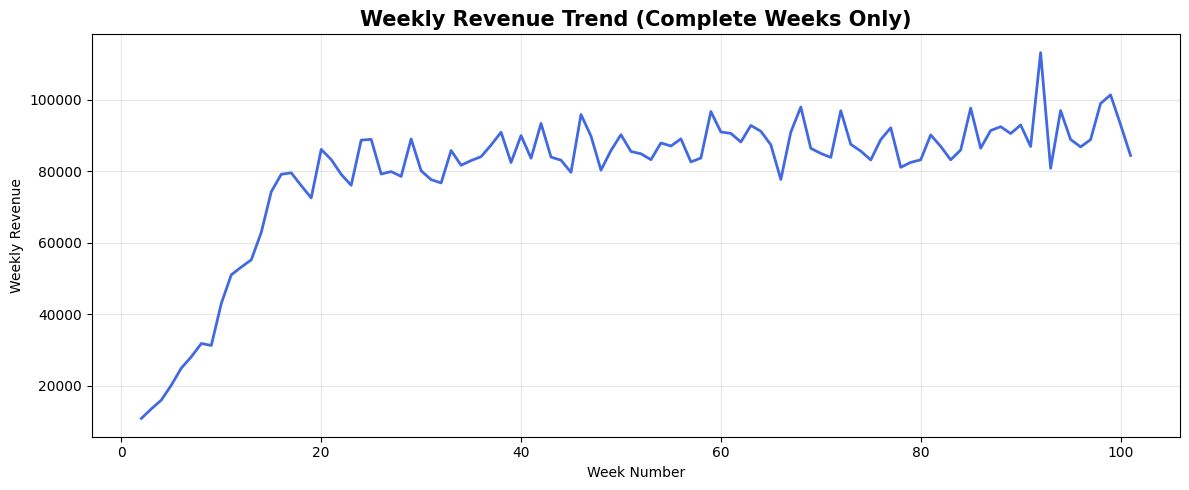

Complete weeks analysed: 100
Average weekly revenue: 79802.83
Highest revenue week: 92


In [86]:

# Visualize weekly revenue trends (complete weeks only)

complete_weeks = weekly_coverage[
    weekly_coverage["days_covered"] == 7
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    complete_weeks["week_no"],
    complete_weeks["revenue"],
    color="royalblue",
    linewidth=2
)

plt.title(
    "Weekly Revenue Trend (Complete Weeks Only)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Week Number")
plt.ylabel("Weekly Revenue")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Complete weeks analysed:", len(complete_weeks))
print("Average weekly revenue:", round(complete_weeks["revenue"].mean(), 2))
print(
    "Highest revenue week:",
    complete_weeks.loc[
        complete_weeks["revenue"].idxmax(), "week_no"
    ]
)


In [87]:

# Identify highest and lowest revenue weeks (complete weeks only)

highest_week = complete_weeks.loc[
    complete_weeks["revenue"].idxmax()
]

lowest_week = complete_weeks.loc[
    complete_weeks["revenue"].idxmin()
]

print("Highest Revenue Week:")
print(f"Week: {int(highest_week['week_no'])}")
print(f"Revenue: {highest_week['revenue']:,.2f}")

print("\nLowest Revenue Week:")
print(f"Week: {int(lowest_week['week_no'])}")
print(f"Revenue: {lowest_week['revenue']:,.2f}")


Highest Revenue Week:
Week: 92
Revenue: 113,192.87

Lowest Revenue Week:
Week: 2
Revenue: 10,821.35


In [88]:
# Calculate revenue generated by each basket

basket_analysis = (
    analysis_data.groupby("basket_id")
    .agg(
        basket_value=("sales_value", "sum"),
        total_items=("product_id", "count"),
        household_key=("household_key", "first")
    )
    .reset_index()
)

print("Total baskets:", len(basket_analysis))

print("\nBasket value statistics:")
print(basket_analysis["basket_value"].describe().round(2))

Total baskets: 275542

Basket value statistics:
count    275542.00
mean         29.24
std          36.12
min           0.01
25%           6.99
50%          17.18
75%          36.39
max         961.49
Name: basket_value, dtype: float64


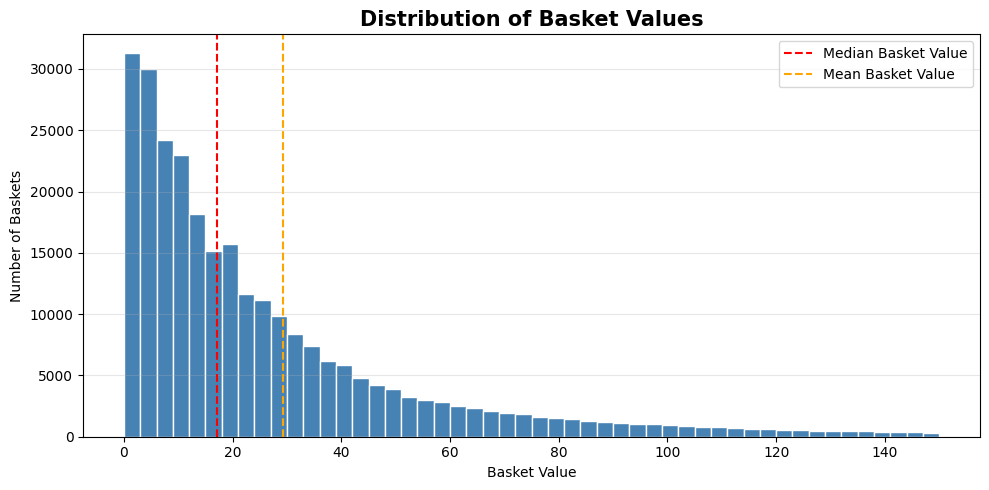

In [89]:
# Visualize basket value distribution

plt.figure(figsize=(10, 5))

plt.hist(
    basket_analysis.loc[
        basket_analysis["basket_value"] <= 150,
        "basket_value"
    ],
    bins=50,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    basket_analysis["basket_value"].median(),
    color="red",
    linestyle="--",
    label="Median Basket Value"
)

plt.axvline(
    basket_analysis["basket_value"].mean(),
    color="orange",
    linestyle="--",
    label="Mean Basket Value"
)

plt.title("Distribution of Basket Values", fontsize=15, fontweight="bold")
plt.xlabel("Basket Value")
plt.ylabel("Number of Baskets")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [90]:
# Calculate customer-level purchasing metrics

customer_analysis = (
    basket_analysis.groupby("household_key")
    .agg(
        total_baskets=("basket_id", "nunique"),
        total_revenue=("basket_value", "sum"),
        avg_basket_value=("basket_value", "mean")
    )
    .reset_index()
)

print("Total customers:", len(customer_analysis))

print("\nCustomer purchasing statistics:")
display(
    customer_analysis[
        ["total_baskets", "total_revenue", "avg_basket_value"]
    ].describe().round(2)
)

Total customers: 2500

Customer purchasing statistics:


,total_baskets,total_revenue,avg_basket_value
count,2500.00,2500.00,2500.00
mean,110.22,3222.99,31.73
std,115.27,3349.03,19.12
min,1.00,8.17,2.39
25%,38.00,970.74,18.43
50%,78.00,2157.75,27.49
75%,142.00,4413.32,40.62
max,1298.00,38319.79,165.83


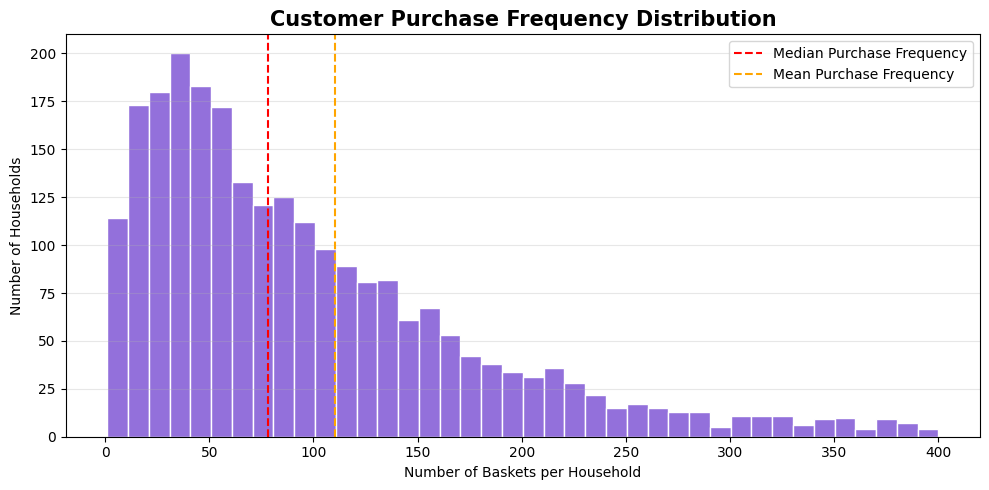

In [91]:
# Visualize customer purchase frequency

plt.figure(figsize=(10, 5))

plt.hist(
    customer_analysis.loc[
        customer_analysis["total_baskets"] <= 400,
        "total_baskets"
    ],
    bins=40,
    color="mediumpurple",
    edgecolor="white"
)

plt.axvline(
    customer_analysis["total_baskets"].median(),
    color="red",
    linestyle="--",
    label="Median Purchase Frequency"
)

plt.axvline(
    customer_analysis["total_baskets"].mean(),
    color="orange",
    linestyle="--",
    label="Mean Purchase Frequency"
)

plt.title("Customer Purchase Frequency Distribution",
          fontsize=15, fontweight="bold")
plt.xlabel("Number of Baskets per Household")
plt.ylabel("Number of Households")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [92]:
# Step 3.5 - Customer Revenue Concentration

# Sort customers from highest to lowest revenue
customer_ranked = customer_analysis.sort_values(
    by="total_revenue",
    ascending=False
).copy()

# Calculate number of customers in top 10% and 20%
top_10_count = int(len(customer_ranked) * 0.10)
top_20_count = int(len(customer_ranked) * 0.20)

# Calculate their contribution to total revenue
total_customer_revenue = customer_ranked["total_revenue"].sum()

top_10_revenue = customer_ranked.head(top_10_count)["total_revenue"].sum()
top_20_revenue = customer_ranked.head(top_20_count)["total_revenue"].sum()

top_10_share = (top_10_revenue / total_customer_revenue) * 100
top_20_share = (top_20_revenue / total_customer_revenue) * 100

print(f"Top 10% Customers: {top_10_count}")
print(f"Revenue Contribution: {top_10_share:.2f}%")

print(f"\nTop 20% Customers: {top_20_count}")
print(f"Revenue Contribution: {top_20_share:.2f}%")

Top 10% Customers: 250
Revenue Contribution: 34.29%

Top 20% Customers: 500
Revenue Contribution: 53.05%


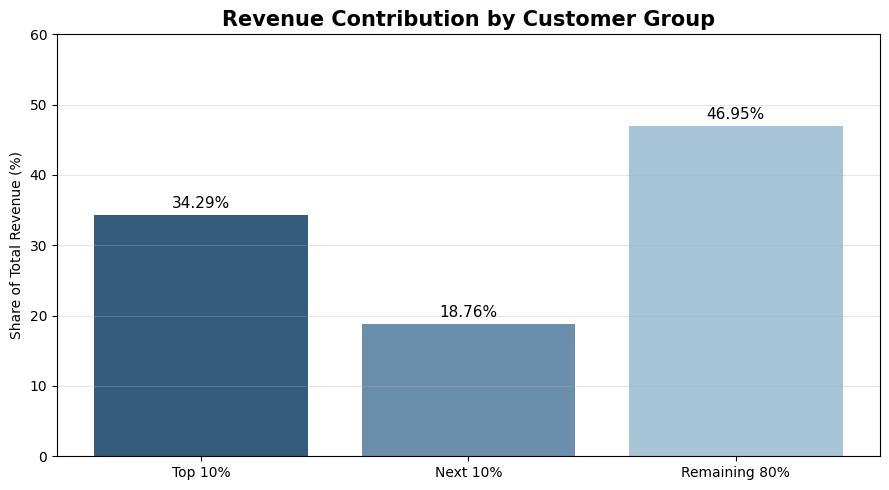

In [93]:
# Visualize customer revenue concentration

next_10_share = top_20_share - top_10_share
remaining_80_share = 100 - top_20_share

groups = ["Top 10%", "Next 10%", "Remaining 80%"]
revenue_shares = [
    top_10_share,
    next_10_share,
    remaining_80_share
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    groups,
    revenue_shares,
    color=["#355C7D", "#6C8EAD", "#A8C4D8"]
)

for bar, value in zip(bars, revenue_shares):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

plt.title("Revenue Contribution by Customer Group",
          fontsize=15, fontweight="bold")
plt.ylabel("Share of Total Revenue (%)")
plt.ylim(0, 60)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [94]:
# Step 3.6 - Department Revenue Analysis

department_sales = (
    analysis_data.groupby("department")["sales_value"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

department_sales["revenue_share"] = (
    department_sales["sales_value"] /
    analysis_data["sales_value"].sum() * 100
)

print("Total departments:", len(department_sales))

print("\nTop 10 Departments by Revenue:")
display(department_sales.head(10).round(2))

Total departments: 43

Top 10 Departments by Revenue:


,department,sales_value,revenue_share
0,GROCERY,4093814.14,50.81
1,DRUG GM,1055358.03,13.10
2,PRODUCE,557452.11,6.92
3,MEAT,548786.81,6.81
4,KIOSK-GAS,544222.28,6.75
5,MEAT-PCKGD,412436.77,5.12
6,DELI,260866.51,3.24
7,PASTRY,121739.86,1.51
8,MISC SALES TRAN,119960.04,1.49
9,NUTRITION,97669.04,1.21


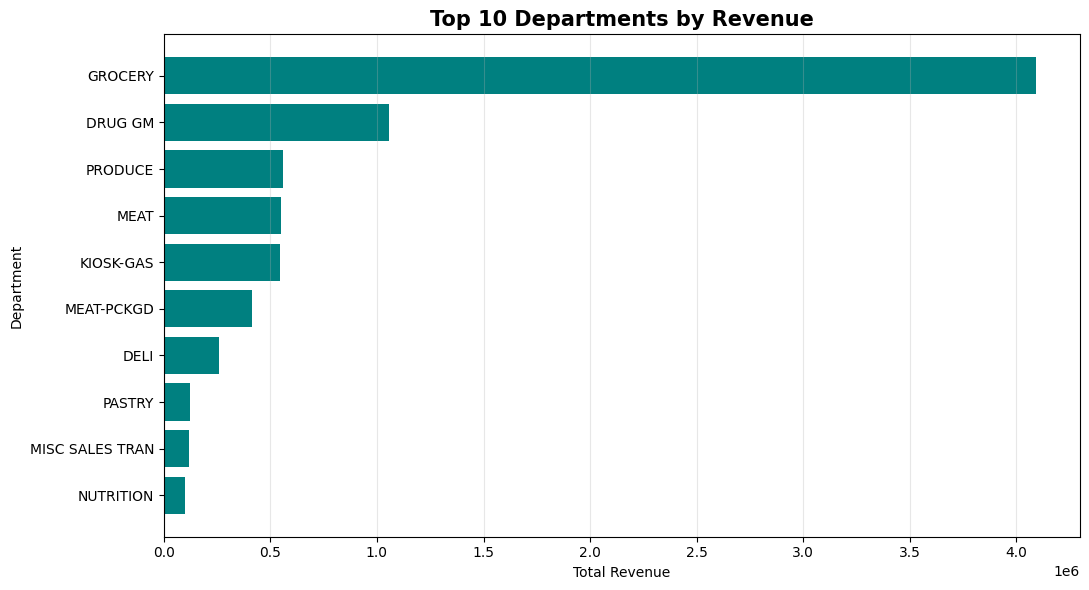

In [95]:
# Visualize top 10 departments by revenue

top_departments = department_sales.head(10).sort_values("sales_value")

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top_departments["department"],
    top_departments["sales_value"],
    color="teal"
)

plt.title("Top 10 Departments by Revenue",
          fontsize=15, fontweight="bold")
plt.xlabel("Total Revenue")
plt.ylabel("Department")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [96]:
# Step 3.7 - Product Category Revenue Analysis

category_sales = (
    analysis_data.groupby("commodity_desc")["sales_value"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_sales["revenue_share"] = (
    category_sales["sales_value"] /
    analysis_data["sales_value"].sum() * 100
)

print("Total product categories:", len(category_sales))

print("\nTop 10 Product Categories by Revenue:")
display(category_sales.head(10).round(2))

Total product categories: 307

Top 10 Product Categories by Revenue:


,commodity_desc,sales_value,revenue_share
0,COUPON/MISC ITEMS,639878.56,7.94
1,SOFT DRINKS,327647.30,4.07
2,BEEF,312103.22,3.87
3,FLUID MILK PRODUCTS,205356.05,2.55
4,CHEESE,189528.18,2.35
5,FRZN MEAT/MEAT DINNERS,160517.17,1.99
6,BAG SNACKS,148375.16,1.84
7,BEERS/ALES,147344.45,1.83
8,FROZEN PIZZA,146037.25,1.81
9,BAKED BREAD/BUNS/ROLLS,145930.85,1.81


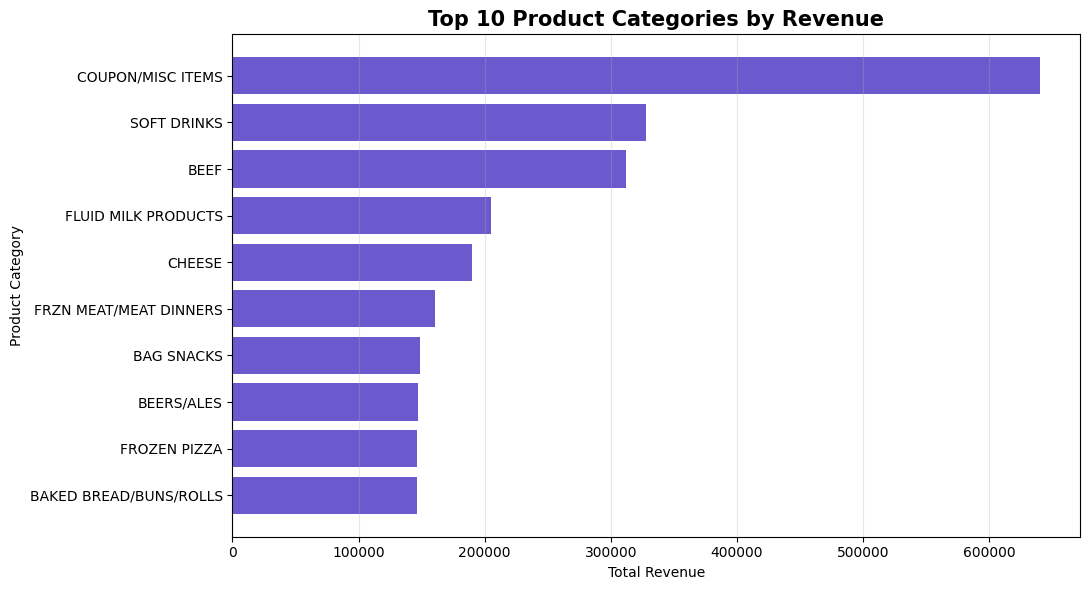

In [97]:
# Visualize top 10 product categories by revenue

top_categories = category_sales.head(10).sort_values("sales_value")

plt.figure(figsize=(11, 6))

plt.barh(
    top_categories["commodity_desc"],
    top_categories["sales_value"],
    color="slateblue"
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [98]:
# Step 4.1 - Calculate RFM metrics

# Identify the last day in the dataset
reference_day = transactions["day"].max() + 1

# Calculate customer-level RFM metrics
rfm = (
    analysis_data.groupby("household_key")
    .agg(
        last_purchase_day=("day", "max"),
        frequency=("basket_id", "nunique"),
        monetary=("sales_value", "sum")
    )
    .reset_index()
)

# Calculate recency
rfm["recency"] = reference_day - rfm["last_purchase_day"]

# Keep only the required columns
rfm = rfm[
    ["household_key", "recency", "frequency", "monetary"]
]

print("Reference Day:", reference_day)
print("Total Customers:", len(rfm))

print("\nRFM Sample:")
display(rfm.head())

print("\nRFM Statistics:")
display(rfm[["recency", "frequency", "monetary"]].describe().round(2))

Reference Day: 712
Total Customers: 2500

RFM Sample:


,household_key,recency,frequency,monetary
0,1,6,85,4330.16
1,2,44,45,1954.34
2,3,9,47,2653.21
3,4,85,30,1200.11
4,5,9,40,779.06



RFM Statistics:


,recency,frequency,monetary
count,2500.00,2500.00,2500.00
mean,26.58,110.22,3222.99
std,62.79,115.27,3349.03
min,1.00,1.00,8.17
25%,2.00,38.00,970.74
50%,7.00,78.00,2157.75
75%,21.00,142.00,4413.32
max,658.00,1298.00,38319.79


In [99]:
print("Most common recency values:")
print(rfm["recency"].value_counts().head(10))

print("\nFrequency-Monetary correlation:")
print(rfm[["frequency", "monetary"]].corr().round(3))

Most common recency values:
recency
1     367
2     262
3     194
4     157
7     117
6     116
5     109
8      85
9      61
10     57
Name: count, dtype: int64

Frequency-Monetary correlation:
           frequency  monetary
frequency      1.000     0.703
monetary       0.703     1.000


In [100]:

# Step 4.2 - Assign RFM scores from 1 to 5

# Recency: lower values indicate more recent purchases.
# Business-defined bands ensure identical recency gets the same score.
rfm["r_score"] = pd.cut(
    rfm["recency"],
    bins=[0, 3, 7, 14, 30, float("inf")],
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: higher purchase frequency is better.
# Average ranking gives identical values the same rank.
rfm["f_score"] = pd.qcut(
    rfm["frequency"].rank(method="average"),
    5,
    labels=False,
    duplicates="drop"
) + 1

# Monetary: higher customer revenue is better.
rfm["m_score"] = pd.qcut(
    rfm["monetary"].rank(method="average"),
    5,
    labels=False,
    duplicates="drop"
) + 1

# Create a combined RFM score
rfm["rfm_score"] = (
    rfm["r_score"] +
    rfm["f_score"] +
    rfm["m_score"]
)

print("RFM Scores Sample:")
display(rfm.head(10))

print("\nCombined RFM Score Distribution:")
print(rfm["rfm_score"].value_counts().sort_index())

print("\nRecency Score Distribution:")
print(rfm["r_score"].value_counts().sort_index())


RFM Scores Sample:


,household_key,recency,frequency,monetary,r_score,f_score,m_score,rfm_score
0,1,6,85,4330.16,4,3,4,11
1,2,44,45,1954.34,1,2,3,6
2,3,9,47,2653.21,3,2,3,8
3,4,85,30,1200.11,1,1,2,4
4,5,9,40,779.06,3,2,2,7
5,6,5,249,5996.16,4,5,5,14
6,7,3,59,3400.05,5,2,4,11
7,8,6,113,5534.97,4,4,5,13
8,9,23,20,797.42,2,1,2,5
9,10,27,9,234.34,2,1,1,4



Combined RFM Score Distribution:
rfm_score
3     214
4     129
5     147
6     167
7     191
8     188
9     204
10    203
11    224
12    198
13    221
14    194
15    220
Name: count, dtype: int64

Recency Score Distribution:
r_score
1    461
2    367
3    350
4    499
5    823
Name: count, dtype: int64


In [101]:
# Step 4.3 - Customer Segmentation

def assign_segment(row):

    r = row["r_score"]
    f = row["f_score"]
    m = row["m_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r <= 2 and f >= 4 and m >= 4:
        return "At Risk"

    elif f >= 4 and m >= 3:
        return "Loyal Customers"

    elif r >= 4 and f >= 2:
        return "Potential Loyalists"

    elif f <= 2 and m <= 2:
        return "Low Engagement"

    else:
        return "Others"


# Recalculate segments using the updated RFM scores
rfm["segment"] = rfm.apply(assign_segment, axis=1)

# Verify that assignments match the current scores
assert (rfm["segment"] == rfm.apply(assign_segment, axis=1)).all()

print("Segments successfully recalculated!")
print("Customer Segment Distribution:")
print(rfm["segment"].value_counts())

print("\nTotal Customers:", len(rfm))
print("Customers Assigned:", rfm["segment"].notna().sum())

Segments successfully recalculated!
Customer Segment Distribution:
segment
Low Engagement         695
Champions              623
Potential Loyalists    494
Others                 361
Loyal Customers        248
At Risk                 79
Name: count, dtype: int64

Total Customers: 2500
Customers Assigned: 2500


In [102]:
# Step 4.3A - Verify updated RFM segmentation

print("Customers with recency 1-3 days:")
print(rfm.loc[rfm["recency"].between(1, 3), "r_score"].value_counts())

print("\nCurrent segment distribution:")
print(rfm["segment"].value_counts())

print("\nCustomers in each RFM score combination:")
print(
    rfm.groupby(["r_score", "f_score", "m_score"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

Customers with recency 1-3 days:
r_score
5    823
Name: count, dtype: int64

Current segment distribution:
segment
Low Engagement         695
Champions              623
Potential Loyalists    494
Others                 361
Loyal Customers        248
At Risk                 79
Name: count, dtype: int64

Customers in each RFM score combination:
r_score  f_score  m_score
5        5        5          220
1        1        1          214
5        4        4           79
4        5        5           72
5        5        4           70
2        2        2           60
5        4        3           57
2        1        1           55
5        3        3           54
4        4        4           52
dtype: int64


In [103]:

# Step 4.3B - Verify segment assignment rules

expected_segments = rfm.apply(assign_segment, axis=1)

assert (rfm["segment"] == expected_segments).all(), (
    "RFM segment assignments do not match the scoring rules."
)

assert len(rfm) == 2500, (
    "Unexpected number of households in RFM analysis."
)

print("RFM validation passed.")
print("All 2,500 households have consistent segment assignments.")


RFM validation passed.
All 2,500 households have consistent segment assignments.


In [104]:

# Step 4.3C - Calculate retail-focused RFM metrics

retail_rfm = (
    retail_data.groupby("household_key")
    .agg(
        last_purchase_day=("day", "max"),
        frequency=("basket_id", "nunique"),
        monetary=("sales_value", "sum")
    )
    .reset_index()
)

# Use the same reference day as the full dataset
retail_rfm["recency"] = reference_day - retail_rfm["last_purchase_day"]

# Compare customer-level RFM metrics
rfm_comparison = rfm[
    ["household_key", "recency", "frequency", "monetary"]
].merge(
    retail_rfm[
        ["household_key", "recency", "frequency", "monetary"]
    ],
    on="household_key",
    suffixes=("_full", "_retail"),
    validate="one_to_one"
)

print("Customers compared:", len(rfm_comparison))

print("\nCustomers with changed RFM metrics:")
for metric in ["recency", "frequency", "monetary"]:
    changed = (
        rfm_comparison[f"{metric}_full"]
        != rfm_comparison[f"{metric}_retail"]
    ).sum()
    print(f"{metric.capitalize()}: {changed} customers")

print("\nAverage RFM metrics:")
display(
    pd.DataFrame({
        "Full Dataset": rfm_comparison[
            ["recency_full", "frequency_full", "monetary_full"]
        ].mean().values,
        "Retail-Focused": rfm_comparison[
            ["recency_retail", "frequency_retail", "monetary_retail"]
        ].mean().values
    }, index=["Recency", "Frequency", "Monetary"]).round(2)
)


Customers compared: 2500

Customers with changed RFM metrics:
Recency: 106 customers
Frequency: 1489 customers
Monetary: 1981 customers

Average RFM metrics:


,Full Dataset,Retail-Focused
Recency,26.58,27.43
Frequency,110.22,100.43
Monetary,3222.99,2953.04


In [105]:

# Step 4.4 - Compare full vs retail-focused RFM segments

# Score retail-focused customers using the same rules
retail_rfm["r_score"] = pd.cut(
    retail_rfm["recency"],
    bins=[0, 3, 7, 14, 30, float("inf")],
    labels=[5, 4, 3, 2, 1]
).astype(int)

retail_rfm["f_score"] = (
    pd.qcut(
        retail_rfm["frequency"].rank(method="average"),
        5,
        labels=False,
        duplicates="drop"
    ) + 1
)

retail_rfm["m_score"] = (
    pd.qcut(
        retail_rfm["monetary"].rank(method="average"),
        5,
        labels=False,
        duplicates="drop"
    ) + 1
)

# Apply the same segmentation rules
retail_rfm["segment"] = retail_rfm.apply(
    assign_segment, axis=1
)

# Compare original and retail-focused segments
segment_comparison = rfm[
    ["household_key", "segment"]
].merge(
    retail_rfm[["household_key", "segment"]],
    on="household_key",
    suffixes=("_full", "_retail"),
    validate="one_to_one"
)

changed_segments = (
    segment_comparison["segment_full"]
    != segment_comparison["segment_retail"]
).sum()

print("Total Customers:", len(segment_comparison))
print("Customers Changing Segments:", changed_segments)
print(
    "Percentage Changing Segments:",
    round(changed_segments / len(segment_comparison) * 100, 2),
    "%"
)

print("\nRetail-Focused Segment Distribution:")
print(retail_rfm["segment"].value_counts())

print("\nFull Dataset Segment Distribution:")
print(rfm["segment"].value_counts())


Total Customers: 2500
Customers Changing Segments: 176
Percentage Changing Segments: 7.04 %

Retail-Focused Segment Distribution:
segment
Low Engagement         687
Champions              606
Potential Loyalists    485
Others                 385
Loyal Customers        265
At Risk                 72
Name: count, dtype: int64

Full Dataset Segment Distribution:
segment
Low Engagement         695
Champions              623
Potential Loyalists    494
Others                 361
Loyal Customers        248
At Risk                 79
Name: count, dtype: int64


In [106]:
# Step 4.5 - RFM Segment Revenue Analysis

segment_analysis = (
    rfm.groupby("segment")
    .agg(
        customers=("household_key", "count"),
        total_revenue=("monetary", "sum"),
        avg_revenue=("monetary", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_recency=("recency", "mean")
    )
    .reset_index()
)

# Calculate each segment's revenue contribution
segment_analysis["revenue_share"] = (
    segment_analysis["total_revenue"] /
    rfm["monetary"].sum() * 100
)

# Calculate percentage of customers in each segment
segment_analysis["customer_share"] = (
    segment_analysis["customers"] /
    len(rfm) * 100
)

# Sort by total revenue
segment_analysis = segment_analysis.sort_values(
    "total_revenue",
    ascending=False
)

print("RFM Segment Performance:")
display(segment_analysis.round(2))

RFM Segment Performance:


,segment,customers,total_revenue,avg_revenue,avg_frequency,avg_recency,revenue_share,customer_share
1,Champions,623,4392687.42,7050.86,233.42,2.84,54.52,24.92
5,Potential Loyalists,494,1083741.62,2193.81,71.56,3.55,13.45,19.76
4,Others,361,888234.77,2460.48,66.97,27.84,11.02,14.44
3,Loyal Customers,248,848817.84,3422.65,157.93,11.62,10.53,9.92
2,Low Engagement,695,452180.72,650.62,26.18,66.58,5.61,27.80
0,At Risk,79,391800.71,4959.50,167.52,46.96,4.86,3.16


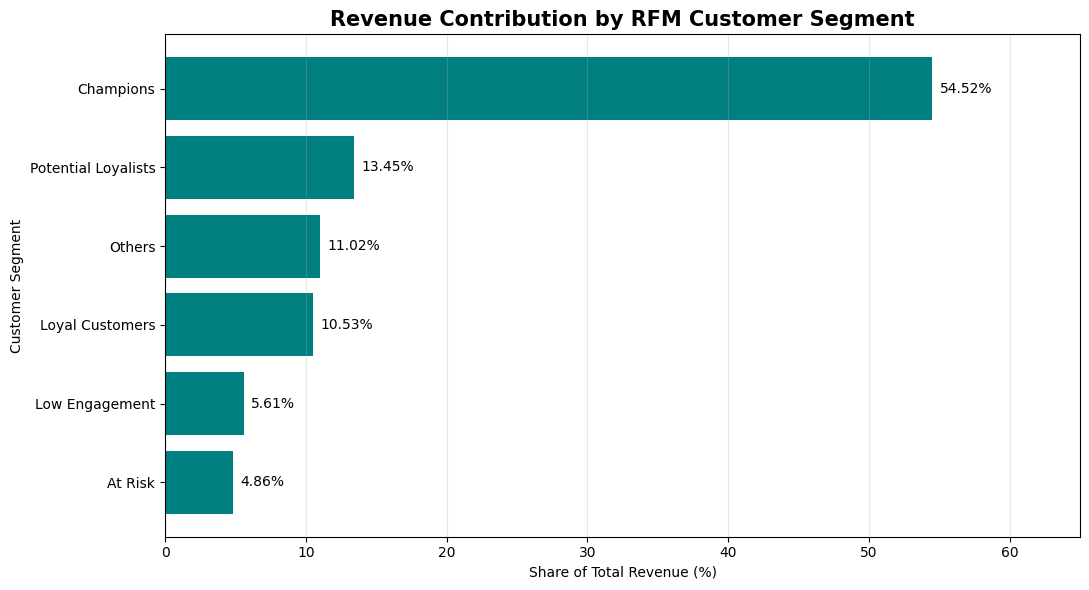

In [107]:
# Step 4.6 - RFM Segment Revenue Contribution

plt.figure(figsize=(11, 6))

bars = plt.barh(
    segment_analysis["segment"],
    segment_analysis["revenue_share"],
    color="teal"
)

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.title(
    "Revenue Contribution by RFM Customer Segment",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Share of Total Revenue (%)")
plt.ylabel("Customer Segment")
plt.xlim(0, 65)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Key Findings & Business Recommendations

## 1. Sales Performance

**Finding:** The retailer generated approximately **8.06 million in recorded revenue** across **275,542 positive-sales shopping baskets** from **2,500 households**. The average basket value was **29.24**.

Weekly revenue increased sharply during the early observation period, followed by fluctuations around a relatively higher revenue level. Across **100 complete seven-day observation windows**, average weekly revenue was **79,802.83**, with the highest weekly revenue of **113,192.87 recorded in Week 92**.

**Recommendation:** Monitor weekly revenue and average basket value to identify unusual fluctuations. Investigate whether changes are associated with customer activity, promotional campaigns, or data coverage before making operational decisions.

## 2. Customer Revenue Concentration

**Finding:** Revenue was concentrated among a relatively small proportion of households:

- The top **10% of households contributed 34.29%** of total revenue.
- The top **20% of households contributed 53.05%** of total revenue.

This indicates that a relatively small group of high-spending households accounts for a substantial share of recorded sales.

**Recommendation:** Prioritize understanding and retaining high-revenue households while monitoring changes in customer revenue concentration over time. Explore targeted engagement strategies without overlooking opportunities to develop lower-spending customers.

## 3. Basket Purchasing Behaviour

**Finding:** The median basket value was **17.18**, considerably lower than the mean of **29.24**, indicating a right-skewed basket-value distribution.

Most baskets generated relatively modest revenue, while a smaller number of high-value baskets increased the overall average.

**Recommendation:** Explore basket-building promotions, complementary product recommendations, and personalized offers. Evaluate their effectiveness through controlled experiments rather than assuming they will increase purchasing activity.

## 4. Department and Product Performance

**Finding:** Revenue varied considerably across departments.

- **Grocery:** 50.81% of total revenue.
- **Drug GM:** 13.10%.
- **Produce:** 6.92%.
- **Meat:** 6.81%.
- **KIOSK-GAS:** 6.75%.

At the commodity level, **COUPON/MISC ITEMS contributed 7.94%** of revenue, followed by **Soft Drinks (4.07%)** and **Beef (3.87%)**.

The COUPON/MISC ITEMS classification includes miscellaneous and gasoline-related transactions and should not be interpreted as a conventional grocery product category.

**Recommendation:** Monitor high-revenue departments and investigate category-specific purchasing patterns. Separate gasoline and miscellaneous transactions when interpreting conventional grocery purchasing behaviour.

## 5. RFM Customer Segmentation

**Finding:** Recency, Frequency, and Monetary (RFM) analysis classified **2,500 households into six behavioural segments** using project-defined scoring rules.

| Customer Segment | Households | Customer Share | Revenue Share |
|---|---:|---:|---:|
| Champions | 623 | 24.92% | 54.52% |
| Potential Loyalists | 494 | 19.76% | 13.45% |
| Others | 361 | 14.44% | 11.02% |
| Loyal Customers | 248 | 9.92% | 10.53% |
| Low Engagement | 695 | 27.80% | 5.61% |
| At Risk | 79 | 3.16% | 4.86% |

### Key RFM Insights

**Champions contributed 54.52% of recorded revenue** despite representing only 24.92% of households.

Champions and Loyal Customers together accounted for **65.05% of total revenue**, while representing **34.84% of households**.

In contrast, the Low Engagement segment represented **27.80% of households** but contributed only **5.61% of revenue**.

The At Risk segment contained 79 households with relatively high historical purchasing frequency and monetary value but lower recent purchasing activity.

These findings highlight substantial differences in historical customer value and purchasing behaviour. However, RFM classifications describe observed activity rather than confirmed future loyalty or churn.

### Business Recommendations by Segment

- **Champions:** Test loyalty benefits, personalized rewards, and retention initiatives to maintain engagement among high-value households.
- **Loyal Customers:** Explore relevant product recommendations and targeted incentives to support continued purchasing.
- **Potential Loyalists:** Encourage additional purchases through personalized promotions and engagement campaigns.
- **At Risk:** Investigate declining recent activity and evaluate targeted re-engagement campaigns.
- **Low Engagement:** Explore cost-effective strategies to encourage additional purchasing while assessing potential customer value.
- **Others:** Investigate the diverse purchasing patterns within this group before developing targeted engagement strategies.

These recommendations are hypotheses for future testing rather than experimentally established outcomes.

## 6. Sensitivity Analysis: Gasoline and Miscellaneous Transactions

**Finding:** Three departments—KIOSK-GAS, MISC SALES TRAN, and MISC. TRANS.—accounted for approximately **8.38% of total recorded revenue**.

To evaluate their influence, a retail-focused comparison dataset was created by excluding transactions belonging to these departments.

### Full Dataset vs Retail-Focused Dataset

| Metric | Full Dataset | Retail-Focused |
|---|---:|---:|
| Transaction Rows | 2,576,882 | 2,546,549 |
| Total Revenue | 8,057,463.08 | 7,382,602.07 |
| Unique Baskets | 275,542 | 251,071 |
| Unique Households | 2,500 | 2,500 |
| Average Recency (days) | 26.58 | 27.43 |
| Average Purchase Frequency | 110.22 | 100.43 |
| Average Customer Monetary Value | 3,222.99 | 2,953.04 |

### Impact on Customer Behaviour

Excluding gasoline and miscellaneous transactions produced the following changes:

- **106 households (4.24%)** experienced a change in recency.
- **1,489 households (59.56%)** experienced a change in purchase frequency.
- **1,981 households (79.24%)** experienced a change in monetary value.
- **176 households (7.04%)** changed RFM customer segments.

Consequently, **92.96% of households retained their original RFM segment classification**.

### Interpretation

Gasoline and miscellaneous transactions materially influence customer spending and purchasing frequency. However, the majority of households retain their RFM classifications after these transactions are excluded.

This suggests that the overall segmentation is relatively stable under the tested exclusion, even though individual purchasing metrics can change substantially.

**Recommendation:** Retain the full dataset for overall retailer performance analysis while using the retail-focused dataset as a sensitivity check. For grocery-focused business questions, evaluate customer behaviour separately from gasoline and miscellaneous purchases.

## Conclusion

The analysis identifies meaningful differences in household purchasing frequency, spending behaviour, basket values, and department-level revenue contribution.

Revenue is concentrated among a relatively small proportion of households, with **Champions and Loyal Customers generating 65.05% of recorded revenue**.

RFM segmentation provides a practical framework for identifying high-value, potentially inactive, and lower-engagement households and developing differentiated engagement strategies.

The sensitivity analysis demonstrates that transaction selection can materially influence customer-level metrics, emphasizing the importance of clearly defining the scope of retail analytics.

Together, these findings provide a foundation for customer retention analysis, merchandising decisions, promotional experimentation, and further investigation of purchasing behaviour.

## Analysis Limitations

- The dataset spans 102 numbered weeks, with incomplete first and final observation weeks. Weekly trend comparisons use 100 complete seven-day observation windows.
- The dataset uses relative day and week numbers rather than actual calendar dates.
- Sales value represents recorded retailer revenue and may differ from customers' out-of-pocket spending.
- The analysis excludes zero-sales transaction rows, which may affect basket counts and customer activity measures.
- RFM segmentation uses project-defined recency thresholds and quantile-based frequency and monetary scores.
- RFM classifications describe historical purchasing behaviour and do not establish actual churn, future loyalty, or causal relationships.
- Frequency and Monetary quantile boundaries were recalculated for the retail-focused sensitivity analysis.
- Demographic information is available for only 801 of the 2,500 households.
- Certain product classifications include gasoline and miscellaneous transactions, requiring careful interpretation.
- The analysis is observational, and the proposed business recommendations have not been experimentally validated.